# Voyager

Simulating the Voyager 1 trajectory

In [1]:
%load_ext autoreload
%autoreload 2

## Imports (hella)

In [2]:
import numpy as np
from numpy.linalg import norm
from scipy.integrate import solve_ivp
from scipy.optimize import fsolve
from scipy.interpolate import CubicSpline
import matplotlib.pyplot as plt
from lamberthub import vallado2013, izzo2015
import plotly.graph_objects as go
from tqdm import tqdm
from pprint import pprint

from cesium.math.time import greg_to_jd
from cesium.constants import DEG_TO_RAD, AU_TO_KM, DAY_TO_SEC, HOUR_TO_SEC, MIN_TO_SEC, KM_TO_M, AU_TO_M
from cesium.orbital.ephemeris import planet_elements_and_rv
from cesium.world.constants import MU_SUN, ECLIPTIC_ANGLE, R_SUN
from cesium.orbital.transformations import radec_to_cartesian
from cesium.orbital.flyby import OrbitalFlyby
from cesium.plotting import plot_flybys, plot_3d
from cesium.physics.dynamics import two_body

from astroquery.jplhorizons import Horizons
from astropy.time import Time
import numpy as np


## Functions

In [3]:
def ECI_wrt_HCI():
    """DCM from J2000 ecliptic to J2000 equatorial coordinates."""
    ang = ECLIPTIC_ANGLE * DEG_TO_RAD
    return np.array([
        [1, 0, 0],
        [0, np.cos(ang), -np.sin(ang)],
        [0, np.sin(ang),  np.cos(ang)],
    ])

def horizons_rv_HCI(t: Time, id: str):
    epoch = t.tdb.jd
    query = Horizons(
        id=id,        # Voyager 1
        location="@10",  # Sun-centered
        epochs=epoch,
    )
    vec = query.vectors(
        refplane="ecliptic",
        aberrations="geometric",
    )
    
    r_HCI = np.array([
        vec["x"][0], vec["y"][0], vec["z"][0]
    ]) * AU_TO_M

    v_HCI = np.array([
        vec["vx"][0], vec["vy"][0], vec["vz"][0]
    ]) * AU_TO_M / DAY_TO_SEC
    
    return r_HCI, v_HCI

# Inplace mutable flybys
def calc_transfer(flyby1: OrbitalFlyby, flyby2: OrbitalFlyby):
    """heliocentric asymptotic arrival and departure velocity vectors, using Lambert
    
    `AA279lambert_curtis.m` signature:
    function [v1_out, v2_out, error_out] = AA279lambert_curtis(mu, r1_in, r2_in, dm, nrev, dtsec)
    """
    r1_HCI, r2_HCI = flyby1.r_HCI, flyby2.r_HCI
    t_transfer = (flyby2.jd - flyby1.jd) * DAY_TO_SEC
    # result = vallado2013(MU_SUN, r1_HCI, r2_HCI, t_transfer, maxiter=10000)                   # short way nargout=2)
    result = izzo2015(MU_SUN, r1_HCI, r2_HCI, t_transfer, M=0)
    # return
    # heliocentric asymptotic arrival and departure velocity vectors
    v1_HCI, v2_HCI = np.array(result[0]).reshape((3,)), np.array(result[1]).reshape((3,))
    flyby1.v_departure_HCI = v1_HCI
    flyby2.v_arrival_HCI = v2_HCI
    
    # planetocentric asymptotic arrival and departure velocity vectors
    flyby1.v_departure_PCI = v1_HCI - flyby1.v_HCI
    flyby2.v_arrival_PCI = v2_HCI - flyby2.v_HCI
    

def sun_two_body(t,x):
    del t
    return two_body(x, MU_SUN)

def transfer_traj(flyby1: OrbitalFlyby, flyby2: OrbitalFlyby):
    t_arr = np.arange(flyby1.jd * DAY_TO_SEC, flyby2.jd * DAY_TO_SEC, 10000)
    sol = solve_ivp(sun_two_body, (t_arr[0], t_arr[-1]), np.concatenate((flyby1.r_HCI, flyby1.v_departure_HCI)), method='LSODA', t_eval=t_arr, rtol=1e-6, atol=1e-9).y
    return t_arr, sol


## Waypoints
https://en.wikipedia.org/wiki/Voyager_1

| Date (UTC) | Event |
|---|---|
| 1977-09-05 12:56:00 | Spacecraft launched |
| 1977-12-10 | Entered asteroid belt |
| 1977-12-19 | Voyager 1 overtakes Voyager 2 |
| 1978-09-08 | Exited asteroid belt |
| 1979-01-06 | Start Jupiter observation phase |
| **1979-03-05** | **Encounter with the Jovian system** |
| 1979-03-05 06:54 | Amalthea flyby at 420,200 km |
| 1979-03-05 12:05:26 | Jupiter closest approach at 348,890 km from center of mass |
| 1979-03-05 15:14 | Io flyby at 20,570 km |
| 1979-03-05 18:19 | Europa flyby at 733,760 km |
| 1979-03-06 02:15 | Ganymede flyby at 114,710 km |
| 1979-03-06 17:08 | Callisto flyby at 126,400 km |
| 1979-04-13 | Jupiter observation phase end |
| 1980-08-22 | Start Saturn observation phase |
| **1980-11-12** | **Encounter with the Saturnian system** |
| 1980-11-12 05:41:21 | Titan flyby at 6,490 km |
| 1980-11-12 22:16:32 | Tethys flyby at 415,670 km |
| 1980-11-12 23:46:30 | Saturn closest approach at 184,300 km from center of mass |
| 1980-11-13 01:43:12 | Mimas flyby at 88,440 km |
| 1980-11-13 01:51:16 | Enceladus flyby at 202,040 km |
| 1980-11-13 06:21:53 | Rhea flyby at 73,980 km |
| 1980-11-13 16:44:41 | Hyperion flyby at 880,440 km |
| 1980-11-14 | Saturn observation phase end |
| 1980-11-14 | Begin extended mission |


### My own

In [ ]:
# Current position in HCI!
# https://theskylive.com/voyager1-info
# 25,834,909,628.1 kilometers from Earth
# Right Ascension: 17h 16m 06s
# Declination: 12° 05’ 13” (apparent coordinates).

# Oct 24, 2026, 20:22:52 Pacific Time
greg_now = (2026, 10, 24, 3, 22, 52)
jd_now = greg_to_jd(*greg_now)
res = planet_elements_and_rv(3, jd_now)
earth_r_now_HCI = res[1] 

ra_deg = (17 + 16/MIN_TO_SEC + 6/HOUR_TO_SEC) * 15
dec_deg = 12 + 5/MIN_TO_SEC + 13/HOUR_TO_SEC
rho_km = 25_834_909_628.1
voy_now_ECI = radec_to_cartesian(ra_deg, dec_deg, rho_km * KM_TO_M, deg=True)

dcm_HCI_wrt_ECI = ECI_wrt_HCI().T
voy_now_HCI = earth_r_now_HCI + dcm_HCI_wrt_ECI @ voy_now_ECI

print(f"Current position in HCI: {voy_now_HCI} m")
# voy_now_HCI = np.array([-4.81565816e12, -2.04958836e13,  1.48291342e13])

Current position in HCI: [-4.68102196e+12 -2.05266037e+13  1.48282415e+13] m


In [ ]:
# name, gregorian date (UTC), planet_number (or None)
flybys_cesium = [
    OrbitalFlyby("Earth Departure", datetime_ymdhms_utc=(1977, 9,  5,  12, 56, 0), planet_num=3),
    OrbitalFlyby("Jupiter Flyby",   datetime_ymdhms_utc=(1979, 3,  5,  12, 5,  26), planet_num=5),
    OrbitalFlyby("Saturn Flyby",    datetime_ymdhms_utc=(1980, 11, 12, 23, 46, 30), planet_num=6),
    OrbitalFlyby("now", datetime_ymdhms_utc=greg_now, r_HCI=voy_now_HCI),
]


N_FLYBYS = len(flybys_cesium)

for flyby in flybys_cesium:
    if flyby.planet_num is not None:
        r,v = planet_elements_and_rv(flyby.planet_num, flyby.jd)[1:3]
        flyby.add_rv_HCI(r,v)

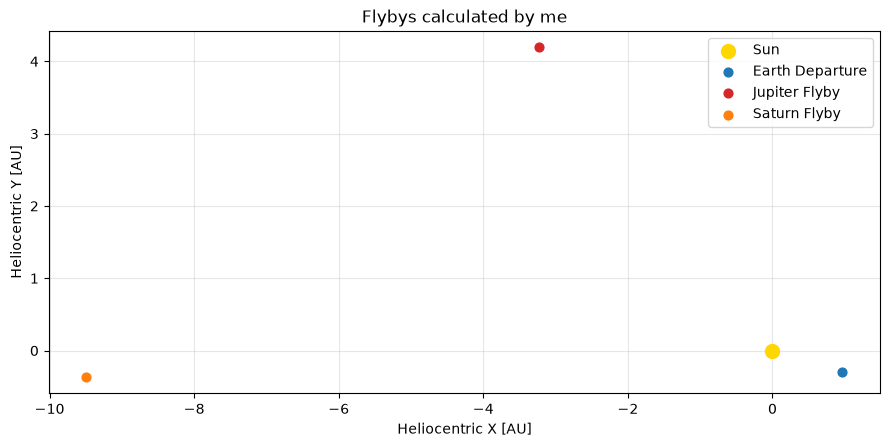

In [6]:
planet_num_to_color = {
    3: "tab:blue",
    5: "tab:red",
    6: "tab:orange",
    None: "tab:green"
    
}
plot_flybys(flybys_cesium[:-1], "Flybys calculated by me", planet_num_to_colors=planet_num_to_color, scale = 1/AU_TO_M)
plt.show()

### JPL

In [ ]:
# Points of interest 

# jpl_r0, jpl_v0 = horizons_rv_HCI(Time("2026-10-24T03:22:52", scale="utc"), "-31")
waypoints = [
    horizons_rv_HCI(Time("1977-9-5T12:56:00", scale="utc"), "3"),
    horizons_rv_HCI(Time("1979-3-5T12:05:26", scale="utc"), "5"),
    horizons_rv_HCI(Time("1980-11-12T23:46:30", scale="utc"), "6"),
    horizons_rv_HCI(Time("2026-10-24T03:22:52", scale="utc"), "-31")
]

# name, gregorian date (UTC), planet_number (or None)
flybys_jpl = [
    OrbitalFlyby("Earth Departure", jd=greg_to_jd(1977, 9,  5,  12, 56, 0), planet_num=3),
    OrbitalFlyby("Jupiter Flyby",   jd=greg_to_jd(1979, 3,  5,  12, 5,  26), planet_num=5),
    OrbitalFlyby("Saturn Flyby",    jd=greg_to_jd(1980, 11, 12, 23, 46, 30), planet_num=6),
    OrbitalFlyby("now", jd=greg_to_jd(*greg_now)),
]

for f,p in zip(flybys_jpl, waypoints):
    f.r_HCI, f.v_HCI = p


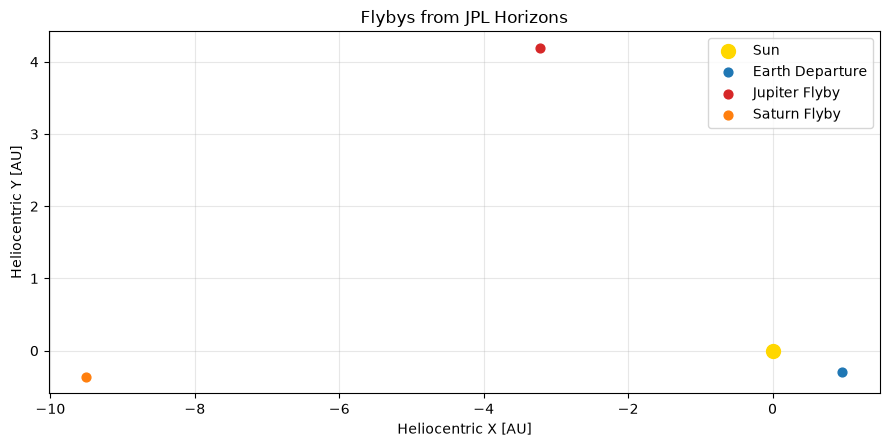

In [8]:
plot_flybys(flybys_jpl[:-1], "Flybys from JPL Horizons", planet_num_to_colors=planet_num_to_color, scale = 1/AU_TO_M)
plt.show()

### Vector differences between both of ours

In [67]:
for mine, theirs in zip(flybys_cesium, flybys_jpl):
    r_mine = mine.r_HCI
    r_theirs = theirs.r_HCI

    diff = norm(r_mine - r_theirs)
    relative_error = diff / norm(r_theirs) * 100

    print(f"{mine.name}")
    print(f"  Cesium distance:   {norm(r_mine) / AU_TO_M:.6f} AU")
    print(f"  JPL distance:      {norm(r_theirs) / AU_TO_M:.6f} AU")
    print(f"  Position error:    {diff / KM_TO_M:,.2f} km")
    print(f"  Relative error:    {relative_error:.6f}%")
    angle_error = np.arctan2(
        norm(np.cross(r_mine, r_theirs)),
        np.dot(r_mine, r_theirs)
    ) / DEG_TO_RAD

    print(f"  Angular error:     {angle_error:.6f} deg")
    print()

Earth Departure
  Cesium distance:   1.008075 AU
  JPL distance:      1.008058 AU
  Position error:    11,241.16 km
  Relative error:    0.007454%
  Angular error:     0.004154 deg

Jupiter Flyby
  Cesium distance:   5.290191 AU
  JPL distance:      5.290111 AU
  Position error:    98,949.03 km
  Relative error:    0.012503%
  Angular error:     0.007111 deg

Saturn Flyby
  Cesium distance:   9.505097 AU
  JPL distance:      9.515742 AU
  Position error:    1,605,958.49 km
  Relative error:    0.112815%
  Angular error:     0.008393 deg

now
  Cesium distance:   172.136902 AU
  JPL distance:      172.142723 AU
  Position error:    138,099,364.43 km
  Relative error:    0.536263%
  Angular error:     0.307255 deg



## Calculating Transfer

In [69]:
for i in range(N_FLYBYS-1):
    calc_transfer(flybys_cesium[i], flybys_cesium[i+1])

### Energy / Scalar sanity check

In [71]:
def calc_h(r,v):
    return norm(np.cross(r, v))

# relevant_flybys = [flybys[i] for i in [1,2,4]]
print("### Flyby HCI velocities ###")
for flyby in flybys_cesium[1:-1]:
    vin = norm(flyby.v_arrival_HCI)
    e_before = calc_h(flyby.r_HCI, flyby.v_arrival_HCI)
    vout = norm(flyby.v_departure_HCI)
    e_after = calc_h(flyby.r_HCI, flyby.v_departure_HCI)
    

    print(f" {flyby.name}(HCI):\n\t{vin:.3f} -> {vout:.3f} m/s\t(diff = {(vout - vin)/vin * 100:.3f}%)")
    print(f"\th: {e_before:.3e} -> {e_after:.3e} m2/s\t(diff = {(e_after - e_before)/e_before * 100:.3f}%)")
    
print()
print("### Flyby PCI velocities ####")
for flyby in flybys_cesium[1:-1]:
    vin = norm(flyby.v_arrival_PCI)
    vout = norm(flyby.v_departure_PCI)
    
    print(f"{flyby.name}(PCI):\n\t{vin:.3f} -> {vout:.3f} m/s\t(diff = {(vout - vin)/vin * 100:.3f}%)")

### Flyby HCI velocities ###
 Jupiter Flyby(HCI):
	12700.341 -> 23506.821 m/s	(diff = 85.088%)
	h: 6.006e+15 -> 1.828e+16 m2/s	(diff = 204.379%)
 Saturn Flyby(HCI):
	20095.977 -> 21506.747 m/s	(diff = 7.020%)
	h: 1.828e+16 -> 2.872e+16 m2/s	(diff = 57.136%)

### Flyby PCI velocities ####
Jupiter Flyby(PCI):
	10942.287 -> 10951.112 m/s	(diff = 0.081%)
Saturn Flyby(PCI):
	15262.596 -> 15092.170 m/s	(diff = -1.117%)


This makes sense because each flyby increases the speed and angular momentum. From PCI it doesn't speed up, but the planet is changing the direction

### Patching

In [73]:

t_arrs = []
planet_r_hci_arr = []
for i in range(N_FLYBYS-1):
    t_arr, sol = transfer_traj(flybys_cesium[i], flybys_cesium[i+1])
    t_arrs.append(t_arr)
    planet_r_hci_arr.append(sol[:3,:].T)

In [57]:
scale = AU_TO_M

plot_3d([p / scale for p in planet_r_hci_arr], t_arrs, bodies={"name": "Sun", "radius": R_SUN/AU_TO_M, "color":"goldenrod"}, title="Voyager 1 trajectory")